# Notebook 06: Final model

The winner of notebook 05 is the final model. This notebook chooses its confidence threshold, tests it on a class it has never seen, and scores it once on the holdout.

- The model is the one saved by notebook 05: fitted on the training compounds and the pool, never on the holdout.
- The threshold and every other choice come from the training compounds (cross-validation). The holdout is scored last, once, and nothing is changed afterwards.
- Main score: macro-F1 over the six drug classes, as in notebook 05.
- Outputs: tables in `reports/tables/`, figures in `reports/figures/06_*.png`, and the threshold added to the model file in `models/`.

## 1. Load the data
### Libraries

In [13]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.neighbors import KNeighborsClassifier
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.svm import SVC

### Plot style
Same palette as notebook 05 (blue, orange, aqua, yellow), no top and right frame.

In [14]:
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

### Data
The features, the labels, the split and the three outputs of notebook 05 that this notebook needs: the winner and its out-of-fold probabilities.

In [15]:
X_all = pd.read_csv("../data/processed/X.csv", index_col="inchikey")
labels = pd.read_csv("../data/labels/labels.csv")
split = pd.read_csv("../data/labels/split.csv")
family_to_class = pd.read_csv("../data/labels/family_to_class.csv").set_index("family")["class"].to_dict()
winner = pd.read_csv("../reports/tables/winner.csv").iloc[0]
oof = pd.read_csv("../reports/tables/oof_winner.csv")
winner[["method", "setting", "target"]]

method             self-training
setting    logreg, threshold 0.9
target                       sum
Name: 0, dtype: object

### Training compounds, holdout and pool

In [16]:
train = split[split.set == "train"].reset_index(drop=True)
holdout = split[split.set == "holdout"].reset_index(drop=True)
pool = labels[labels.status == "unlabeled"]

assert set(pool.inchikey).isdisjoint(split.inchikey)
assert set(holdout.inchikey).isdisjoint(train.inchikey)
assert (oof[oof.repeat == 0].inchikey.values == train.inchikey.values).all(), "rerun notebook 05"
X_train = X_all.loc[train.inchikey].values
X_pool = X_all.loc[pool.inchikey].values
X_holdout = X_all.loc[holdout.inchikey].values
len(train), len(holdout), len(pool)

(511, 126, 933)

### Families and classes
Same definitions as notebook 05. `M` has one row per family and one column per class.

In [17]:
FAMILIES = sorted(family_to_class)
N_FAMILIES = len(FAMILIES)
CLASSES = np.array(sorted(set(family_to_class.values())))
DRUGS = ["cannabinoid", "depressant", "dissociative", "opioid", "psychedelic", "stimulant"]
FAMILY_CLASS = np.array([family_to_class[f] for f in FAMILIES])
M = (FAMILY_CLASS[:, None] == CLASSES[None, :]).astype(float)

y_train = train.family.map({f: i for i, f in enumerate(FAMILIES)}).values
y_pool = np.full(len(pool), -1)
true_class = train["class"].values

### Answer and confidence
The answer is the class given by the winner's target, as in the app: with **sum** the most likely class and its probability, with **top** the class of the most likely family and that family's probability. The confidence is compared with the threshold.

In [18]:
def answer(proba):
    if winner.target == "sum":
        class_proba = proba @ M
        return CLASSES[class_proba.argmax(axis=1)], class_proba.max(axis=1)
    return FAMILY_CLASS[proba.argmax(axis=1)], proba.max(axis=1)


def drug_f1(true, pred):
    return f1_score(true, pred, labels=DRUGS, average="macro", zero_division=0)

### The saved model
Notebook 05 saved the best setting of each method. The file of the winner is loaded, and it must be the winner's setting. `family_proba` is the one of notebook 05 and the app, reduced to the self-training model type (a model from another method needs its branch copied from notebook 05).

In [19]:
assert winner.method == "self-training", "copy the fit function and family_proba branch of the winner from notebook 05"
saved = joblib.load(f"../models/{winner.method.replace('-', '_')}.joblib")
assert saved["setting"] == winner.setting and saved["feature_names"] == list(X_all.columns)


def family_proba(model, X):
    m = model["model"]
    full = np.zeros((len(X), N_FAMILIES))
    full[:, m.classes_] = m.predict_proba(X)
    return full

## 2. Threshold
The model answers "uncertain" when its confidence is below a threshold. The threshold is read from the out-of-fold predictions of notebook 05 (grouped cross-validation on the training compounds, 3 repeats), never from the holdout.

- Rule: the lowest threshold whose accuracy on the answered compounds is at least 0.85 while at least 60% of the compounds are answered. (The first version of the project used 0.75; that value is already met at the lowest threshold tried, 0.30, where only 3% of compounds are called uncertain, so the threshold would do nothing.)
- If no threshold meets it, the one with the best accuracy among those answering at least 60% is taken.

### Table of thresholds
The values are means over the 3 repeats.

In [20]:
oof_proba = [part[FAMILIES].values for _, part in oof.groupby("repeat")]


def threshold_row(t):
    rows = []
    for proba in oof_proba:
        pred, conf = answer(proba)
        kept = conf >= t
        rows.append([kept.mean(), (pred[kept] == true_class[kept]).mean(),
                     drug_f1(true_class[kept], pred[kept])])
    return dict(zip(["answered_share", "accuracy_answered", "drug_f1_answered"], np.mean(rows, axis=0)))


thresholds = pd.DataFrame([{"threshold": t, **threshold_row(t)} for t in np.round(np.arange(0.30, 0.801, 0.05), 2)])
thresholds.to_csv("../reports/tables/threshold_table.csv", index=False)
thresholds.round(3)

,threshold,answered_share,accuracy_answered,drug_f1_answered
0,0.30,0.970,0.782,0.818
1,0.35,0.919,0.805,0.838
2,0.40,0.849,0.831,0.863
3,0.45,0.785,0.858,0.887
4,0.50,0.727,0.885,0.905
5,0.55,0.676,0.909,0.924
6,0.60,0.626,0.922,0.934
7,0.65,0.583,0.941,0.954
8,0.70,0.543,0.951,0.960
9,0.75,0.497,0.960,0.971


### Chosen threshold

In [21]:
enough = thresholds[thresholds.answered_share >= 0.6]
good = enough[enough.accuracy_answered >= 0.85]
THRESHOLD = good.threshold.min() if len(good) else enough.set_index("threshold").accuracy_answered.idxmax()
print(f"threshold {THRESHOLD}" + ("" if len(good) else " (rule not met, best accuracy among those answering at least 60%)"))
thresholds[thresholds.threshold == THRESHOLD].round(3)

threshold 0.45


,threshold,answered_share,accuracy_answered,drug_f1_answered
3,0.45,0.785,0.858,0.887


### Chart

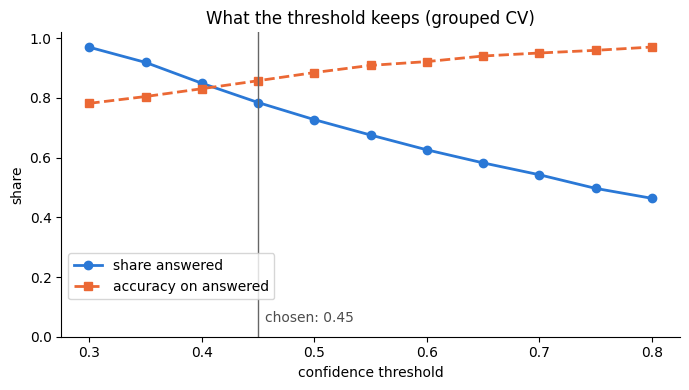

In [22]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds.threshold, thresholds.answered_share, marker="o", ms=6, lw=2, label="share answered")
ax.plot(thresholds.threshold, thresholds.accuracy_answered, marker="s", ms=6, lw=2, ls="--", label="accuracy on answered")
ax.axvline(THRESHOLD, color="0.4", lw=1)
ax.annotate(f"chosen: {THRESHOLD}", (THRESHOLD, 0.05), xytext=(5, 0), textcoords="offset points", color="0.3")
ax.set_xlabel("confidence threshold")
ax.set_ylabel("share")
ax.set_ylim(0, 1.02)
ax.set_title("What the threshold keeps (grouped CV)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 0.1))
fig.tight_layout()
fig.savefig("../reports/figures/06_threshold.png", dpi=150, bbox_inches="tight")

## 3. Rejection test
The model has to say "uncertain" for a drug class it has never seen. Each class in turn is left out of the labeled compounds (the pool is kept, as in the app); the model is fitted again, and the compounds of the left-out class are counted as uncertain when their confidence is below the threshold. The comparison is the uncertain share of normal cross-validation predictions. A model that knows what it does not know has a much higher share for the left-out class.

### Fit function of the winner
Self-training with a base classifier and a threshold, written in the setting name (`logreg, threshold 0.9`).

In [23]:
BASES = {
    "logreg": LogisticRegression(C=10, class_weight="balanced", max_iter=2000),
    "svm": SVC(C=10, class_weight="balanced", probability=True, random_state=0),
    "knn": KNeighborsClassifier(n_neighbors=7, metric="cosine", weights="distance"),
}
base, pseudo_threshold = winner.setting.split(", threshold ")


def fit_winner(X, y):
    return {"model": SelfTrainingClassifier(clone(BASES[base]), threshold=float(pseudo_threshold)).fit(X, y)}

### Check
Refitting on all training compounds and the pool must give the saved model's probabilities.

In [24]:
X_fit = np.vstack([X_train, X_pool])
y_fit = np.concatenate([y_train, y_pool])
refit = fit_winner(X_fit, y_fit)
assert np.allclose(family_proba(refit, X_holdout), family_proba(saved["model"], X_holdout), atol=1e-6)

### Leave one class out
The seven fits run in parallel.

In [25]:
def confidence_without(cls):
    keep = true_class != cls
    model = fit_winner(np.vstack([X_train[keep], X_pool]), np.concatenate([y_train[keep], y_pool]))
    return answer(family_proba(model, X_train[~keep]))[1]


confidences = dict(zip(CLASSES, joblib.Parallel(n_jobs=-1)(joblib.delayed(confidence_without)(c) for c in CLASSES)))
rejection = pd.DataFrame({
    "left_out_class": CLASSES,
    "compounds": [len(confidences[c]) for c in CLASSES],
    "uncertain_share": [(confidences[c] < THRESHOLD).mean() for c in CLASSES]})
NORMAL_UNCERTAIN = np.mean([(answer(p)[1] < THRESHOLD).mean() for p in oof_proba])
rejection["normal_uncertain_share"] = NORMAL_UNCERTAIN
rejection.to_csv("../reports/tables/rejection_test.csv", index=False)
print(f"uncertain share of normal predictions: {NORMAL_UNCERTAIN:.2f}")
rejection.round(2)

uncertain share of normal predictions: 0.22


,left_out_class,compounds,uncertain_share
0,cannabinoid,73,0.37
1,depressant,49,0.24
2,dissociative,24,0.33
3,opioid,119,0.34
4,other,72,0.28
5,psychedelic,67,0.39
6,stimulant,107,0.27


### Chart

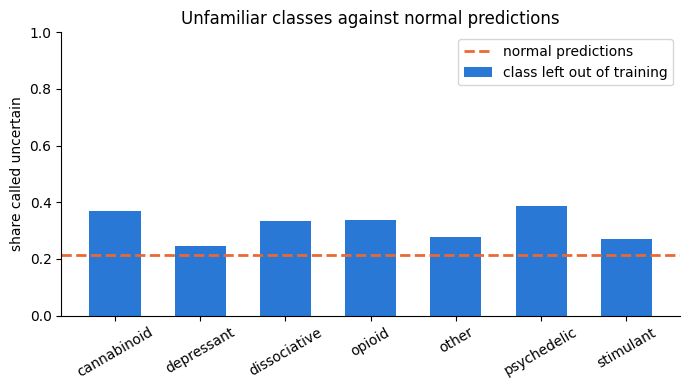

In [26]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rejection.left_out_class, rejection.uncertain_share, width=0.6, label="class left out of training")
ax.axhline(NORMAL_UNCERTAIN, color="#eb6834", lw=2, ls="--", label="normal predictions")
ax.set_ylabel("share called uncertain")
ax.set_ylim(0, 1)
ax.set_title("Unfamiliar classes against normal predictions")
ax.tick_params(axis="x", rotation=30)
ax.legend()
fig.tight_layout()
fig.savefig("../reports/figures/06_rejection_test.png", dpi=150, bbox_inches="tight")

## 4. Holdout
The holdout compounds are scored here, once. Nothing in this notebook or the project is changed because of these numbers.

### Predictions

In [27]:
proba = family_proba(saved["model"], X_holdout)
pred, conf = answer(proba)
true = holdout["class"].values
predicted_family = np.array(FAMILIES)[proba.argmax(axis=1)]

predictions = holdout[["inchikey", "name", "family", "class"]].assign(
    predicted_family=predicted_family, predicted_class=pred, confidence=conf.round(3), uncertain=conf < THRESHOLD)
predictions.to_csv("../reports/tables/holdout_predictions.csv", index=False)

### Scores
The interval comes from 1,000 resamples of the holdout compounds (seed 0).

In [28]:
rng = np.random.default_rng(0)
boot = [drug_f1(true[i], pred[i]) for i in (rng.integers(0, len(true), len(true)) for _ in range(1000))]
low, high = np.percentile(boot, [2.5, 97.5])
answered = conf >= THRESHOLD

results = pd.Series({
    "holdout_compounds": len(holdout),
    "drug_f1": drug_f1(true, pred),
    "drug_f1_low": low,
    "drug_f1_high": high,
    "accuracy": (pred == true).mean(),
    "family_accuracy": (predicted_family == holdout.family.values).mean(),
    "other_recall": (pred[true == "other"] == "other").mean(),
    "threshold": THRESHOLD,
    "uncertain_share": 1 - answered.mean(),
    "accuracy_answered": (pred[answered] == true[answered]).mean(),
    "cv_drug_f1": winner.drug_f1,
    "cv_spread": winner.spread})
results.to_frame().T.to_csv("../reports/tables/holdout_results.csv", index=False)
results.round(3)

holdout_compounds    126.000
drug_f1                0.796
drug_f1_low            0.705
drug_f1_high           0.866
accuracy               0.754
family_accuracy        0.730
other_recall           0.722
threshold              0.450
uncertain_share        0.190
accuracy_answered      0.833
cv_drug_f1             0.806
cv_spread              0.013
dtype: float64

### Scores per class

In [29]:
precision, recall, f1, count = precision_recall_fscore_support(true, pred, labels=CLASSES, zero_division=0)
per_class = pd.DataFrame({"class": CLASSES, "compounds": count, "precision": precision, "recall": recall, "f1": f1})
per_class.to_csv("../reports/tables/holdout_per_class.csv", index=False)
per_class.round(2)

,class,compounds,precision,recall,f1
0,cannabinoid,18,0.75,0.50,0.60
1,depressant,12,0.82,0.75,0.78
2,dissociative,6,1.00,0.83,0.91
3,opioid,29,0.76,0.76,0.76
4,other,18,0.46,0.72,0.57
5,psychedelic,16,1.00,0.69,0.81
6,stimulant,27,0.87,0.96,0.91


### Confusion matrix
Rows are the true class, columns the answer. The colour is the share of the row; the numbers are compounds.

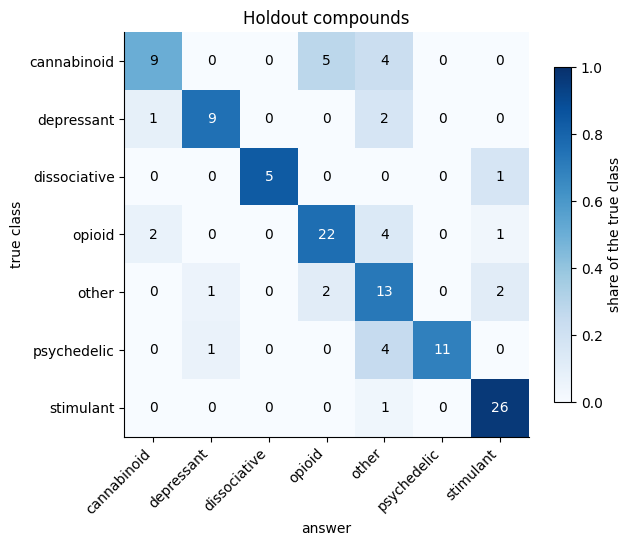

In [30]:
counts = confusion_matrix(true, pred, labels=CLASSES)
shares = counts / counts.sum(axis=1, keepdims=True).clip(1)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
for i, j in np.ndindex(counts.shape):
    ax.text(j, i, counts[i, j], ha="center", va="center", color="white" if shares[i, j] > 0.5 else "black")
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel("answer")
ax.set_ylabel("true class")
ax.set_title("Holdout compounds")
fig.colorbar(image, label="share of the true class", shrink=0.8)
fig.tight_layout()
fig.savefig("../reports/figures/06_holdout_confusion.png", dpi=150, bbox_inches="tight")

### Recall: cross-validation against holdout
The holdout bars rest on few compounds per class (see the table above), so they move by several points per compound.

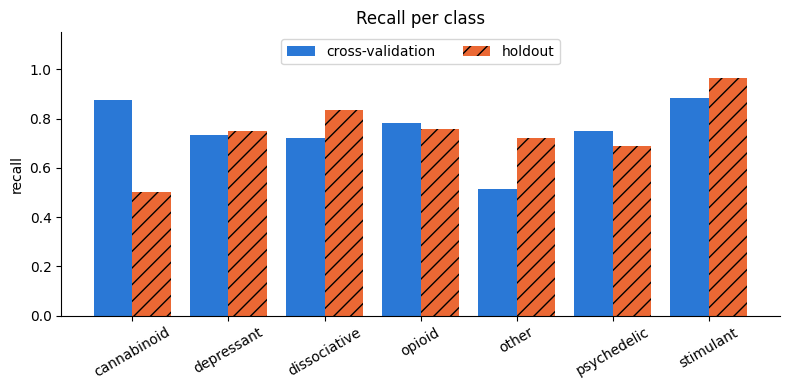

In [31]:
def recalls(true, pred):
    counts = confusion_matrix(true, pred, labels=CLASSES)
    return np.diag(counts) / counts.sum(axis=1).clip(1)


cv_recall = np.mean([recalls(true_class, answer(p)[0]) for p in oof_proba], axis=0)
per_class["cv_recall"] = cv_recall
per_class.to_csv("../reports/tables/holdout_per_class.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(CLASSES))
ax.bar(x - 0.2, cv_recall, width=0.4, label="cross-validation")
ax.bar(x + 0.2, recalls(true, pred), width=0.4, hatch="//", label="holdout")
ax.set_xticks(x, CLASSES, rotation=30)
ax.set_ylabel("recall")
ax.set_ylim(0, 1.15)
ax.set_title("Recall per class")
ax.legend(ncol=2, loc="upper center")
fig.tight_layout()
fig.savefig("../reports/figures/06_holdout_recall.png", dpi=150, bbox_inches="tight")

### Wrong answers
Highest confidence first.

In [32]:
wrong = predictions[predictions["class"] != predictions.predicted_class]
wrong.sort_values("confidence", ascending=False)[["name", "family", "predicted_family", "class", "predicted_class", "confidence"]]

,name,family,predicted_family,class,predicted_class,confidence
54,Cinazepam,benzodiazepine,carboxamide-ester-SC,depressant,cannabinoid,0.887
118,Pyrithyldione,depressant-other,other-medicine,depressant,other,0.765
98,Muscimol,psychedelic-other,other-medicine,psychedelic,other,0.706
31,5-chloro AKB48,carboxamide-ester-SC,other-medicine,cannabinoid,other,0.619
65,Dextrorphan,morphinan,other-medicine,opioid,other,0.609
113,Pentaerythritol,other-medicine,stimulant-other,other,stimulant,0.603
23,4-Fluoromethylphenidate,stimulant-other,other-medicine,stimulant,other,0.560
79,Harmine,psychedelic-other,other-medicine,psychedelic,other,0.549
60,Deoxymethoxetamine,arylcyclohexylamine,cathinone,dissociative,stimulant,0.548
50,Cephalexin,other-medicine,morphinan,other,opioid,0.547


## 5. Save the threshold
The threshold is added to the winner's model file; the other keys are unchanged, so the app reads it without any code change. The other three model files keep the app's provisional default.

In [33]:
path = f"../models/{winner.method.replace('-', '_')}.joblib"
saved["threshold"] = float(THRESHOLD)
saved.pop("provisional", None)
joblib.dump(saved, path)

reloaded = joblib.load(path)
assert reloaded["threshold"] == THRESHOLD
assert np.allclose(family_proba(reloaded["model"], X_holdout), proba)
pd.DataFrame([{"method": winner.method, "setting": winner.setting, "target": winner.target,
               "threshold": THRESHOLD, "cv_drug_f1": winner.drug_f1, "holdout_drug_f1": results.drug_f1}]
             ).to_csv("../reports/tables/final_model.csv", index=False)

## 6. Summary

In [34]:
print(f"model: {winner.method} ({winner.setting}, target {winner.target}), threshold {THRESHOLD}")
print(f"drug macro-F1: CV {winner.drug_f1:.3f} +/- {winner.spread:.3f}, holdout {results.drug_f1:.3f} (95% interval {low:.2f} to {high:.2f})")
print(f"holdout: {results.uncertain_share:.0%} uncertain, accuracy on the answered {results.accuracy_answered:.2f}")
print(f"unfamiliar class called uncertain: {rejection.uncertain_share.mean():.0%} on average, against {NORMAL_UNCERTAIN:.0%} for normal predictions")

model: self-training (logreg, threshold 0.9, target sum), threshold 0.45
drug macro-F1: CV 0.806 +/- 0.013, holdout 0.796 (95% interval 0.70 to 0.87)
holdout: 19% uncertain, accuracy on the answered 0.83
unfamiliar class called uncertain: 32% on average, against 22% for normal predictions
